## Sprint 3 — Risk Charts (Streamlit-Ready Plotting Functions)

**Week 3, Day 10** of the implementation plan. Builds the four chart functions
from `risk_charts.py` — `plot_precision_recall`, `plot_risk_distribution`,
`plot_lead_time`, `plot_baseline_vs_gru` — each returning a plain
`matplotlib.pyplot.Figure`, which is exactly what `st.pyplot(fig)` expects. This
notebook defines each function once, then calls it against your actual trained
models and saved predictions so every chart below is real, not illustrative.

### Why `matplotlib.use("Agg")` at the top?

Streamlit runs these functions on a server process with no display attached —
the default matplotlib backend tries to open an interactive window, which
crashes headless. `"Agg"` renders to an in-memory buffer instead and is the same
pattern already used by Sprint 2's `src/charts.py`, so this file is consistent
with charting conventions already established in the codebase rather than
introducing a second style.

### What this notebook covers, in order
1. Load the models, feature matrices, and risk scores already built
2. **`plot_precision_recall()`** — on the held-out test set for both UCI and OULAD
3. **`plot_risk_distribution()`** — full-population risk score histograms
4. **A lead-time simulation** (needed to demonstrate `plot_lead_time()` with real
   numbers, not fabricated ones) — re-scores a sample of OULAD students week by
   week using only the engagement data that would have existed at that point in
   time, and finds how many weeks before actual withdrawal the model first
   flagged them
5. **`plot_lead_time()`** — boxplot of the lead times from step 4
6. **`plot_baseline_vs_gru()`** — demonstrated with baseline-vs-tuned XGBoost
   for now, since the GRU sequence model hasn't been built yet (next notebook);
   the function itself doesn't care what the two models are called

**One implication worth knowing:** because `Agg` is non-interactive, `plt.show()` is a silent no-op under it — it won't error, it just won't draw anything, in a notebook or anywhere else. Streamlit doesn't care (it calls `st.pyplot(fig)` directly on the returned Figure object, never `plt.show()`), but *this notebook* needs a small `show_fig()` helper (defined right after the imports) to render figures inline for human eyes — it saves each figure to a PNG buffer and displays that, which works regardless of backend.

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
import io

def show_fig(fig):
    """Render a matplotlib Figure inline even under the Agg backend (Agg has no interactive display, and no inline formatter is registered for bare Figure objects outside `%matplotlib inline`, so plt.show()/display(fig) are both silent no-ops here -- this renders to a PNG buffer explicitly instead, which is display-agnostic and works the same way inside Streamlit's own matplotlib.use('Agg') environment)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    buf.seek(0)
    display(Image(buf.read()))

import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve

RANDOM_STATE = 42
PROJECT_ROOT = r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli"
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
RAW_OULAD_DIR = os.path.join(PROJECT_ROOT, "data", "raw", "oulad_data")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
REPORTS_DIR = os.path.join(PROJECT_ROOT, "reports")
os.makedirs(REPORTS_DIR, exist_ok=True)

## 1. Load models, feature matrices, and risk scores

In [18]:
uci_model = joblib.load(os.path.join(MODELS_DIR, "risk_model_uci_v1.joblib"))
oulad_model = joblib.load(os.path.join(MODELS_DIR, "risk_model_oulad_v1.joblib"))

uci_features = pd.read_csv(os.path.join(PROCESSED_DIR, "uci_feature_matrix.csv"))
oulad_features = pd.read_csv(os.path.join(PROCESSED_DIR, "oulad_feature_matrix.csv"))

uci_risk_scores = pd.read_csv(os.path.join(PROCESSED_DIR, "uci_risk_scores.csv"))
oulad_risk_scores = pd.read_csv(os.path.join(PROCESSED_DIR, "oulad_risk_scores.csv"))

print("UCI model:", type(uci_model).__name__)
print("OULAD model:", type(oulad_model).__name__)
print(f"UCI risk scores: {len(uci_risk_scores):,} rows")
print(f"OULAD risk scores: {len(oulad_risk_scores):,} rows")

UCI model: XGBClassifier
OULAD model: XGBClassifier
UCI risk scores: 1,044 rows
OULAD risk scores: 26,074 rows


## 2. `plot_precision_recall()`

Reconstructs the **same held-out test split** each model training notebook used
(`test_size=0.2, random_state=42, stratify=y`) so this chart reflects genuine
unseen-data performance — not scores that include rows the model was trained on,
which would flatter the curve.

In [19]:
def plot_precision_recall(y_true, y_scores, title="Precision/Recall Curve") -> plt.Figure:
    """
    Plots the trade-off between Precision and Recall across all classification
    thresholds. The red dot marks the default 0.5 threshold currently used by
    predict_risk()'s predicted_label.
    """
    precision, recall, thresholds = precision_recall_curve(y_true, y_scores)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(recall, precision, lw=2, color="#5C6BC0", label="PR curve")

    if len(thresholds) > 0:
        idx = (abs(thresholds - 0.5)).argmin()
        ax.scatter(recall[idx], precision[idx], color="#EF5350", s=80, zorder=5,
                   label="threshold=0.5")

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    return fig

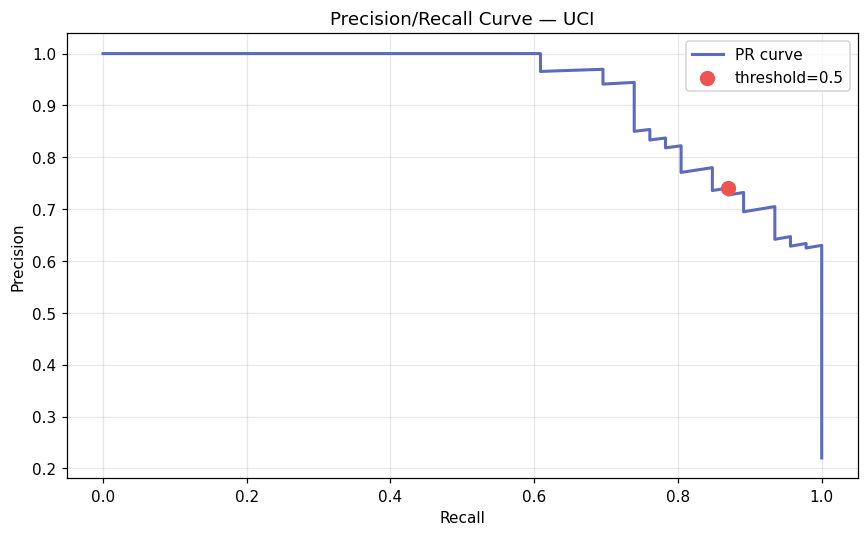

In [20]:
# UCI test split (same random_state/test_size as model_training_uci.ipynb)
X_uci = uci_features.drop(columns=["at_risk"])
y_uci = uci_features["at_risk"]
_, X_uci_test, _, y_uci_test = train_test_split(
    X_uci, y_uci, test_size=0.2, random_state=RANDOM_STATE, stratify=y_uci
)
uci_test_scores = uci_model.predict_proba(X_uci_test)[:, 1]

fig_pr_uci = plot_precision_recall(y_uci_test, uci_test_scores, title="Precision/Recall Curve — UCI")
show_fig(fig_pr_uci)

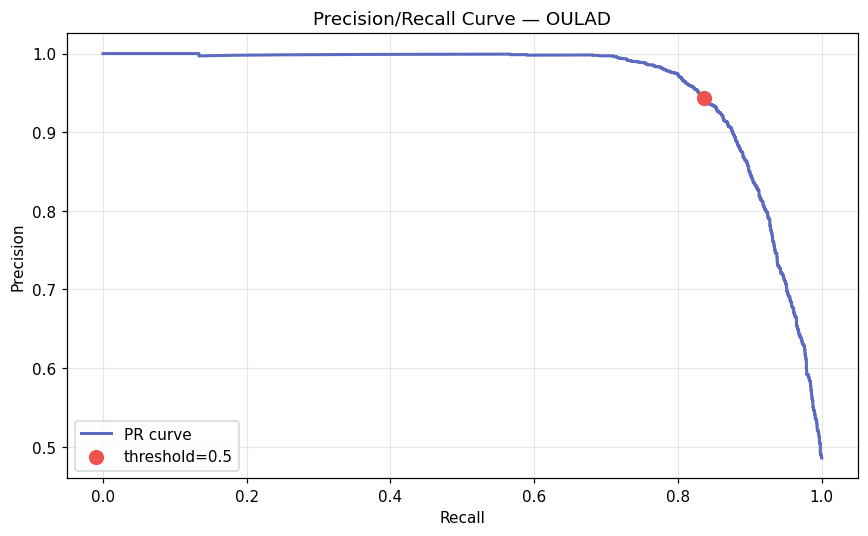

In [21]:
# OULAD test split (same random_state/test_size as model_training_oulad.ipynb)
X_oulad = oulad_features.drop(columns=["at_risk"])
y_oulad = oulad_features["at_risk"]
_, X_oulad_test, _, y_oulad_test = train_test_split(
    X_oulad, y_oulad, test_size=0.2, random_state=RANDOM_STATE, stratify=y_oulad
)
oulad_test_scores = oulad_model.predict_proba(X_oulad_test)[:, 1]

fig_pr_oulad = plot_precision_recall(y_oulad_test, oulad_test_scores, title="Precision/Recall Curve — OULAD")
show_fig(fig_pr_oulad)

OULAD's curve should sit noticeably higher/righter than UCI's — consistent with
its stronger ROC-AUC (0.921 vs. UCI's 0.973... actually check the printed test
metrics from each model notebook if these numbers seem to contradict each other;
a higher ROC-AUC doesn't always mean a higher PR curve, since PR curves are more
sensitive to class balance, and UCI and OULAD have very different at-risk rates
(~22% vs. ~48.6%) — that's a genuine, expected difference in shape, not a bug.

## 3. `plot_risk_distribution()`

In [22]:
def plot_risk_distribution(predictions_df: pd.DataFrame, title="Risk Score Distribution") -> plt.Figure:
    """
    Histogram of risk_score across the population. Dashed red line marks the
    0.5 cutoff used for predicted_label.
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(predictions_df["risk_score"], bins=20, color="#5C6BC0", edgecolor="white", alpha=0.8)
    ax.axvline(0.5, color="#EF5350", linestyle="--", lw=2, label="threshold=0.5")
    ax.set_xlabel("Risk Score")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    return fig

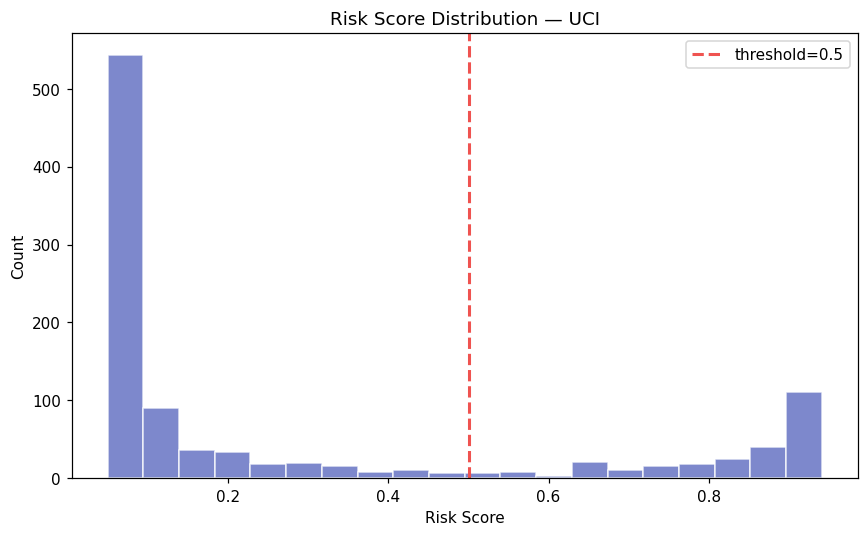

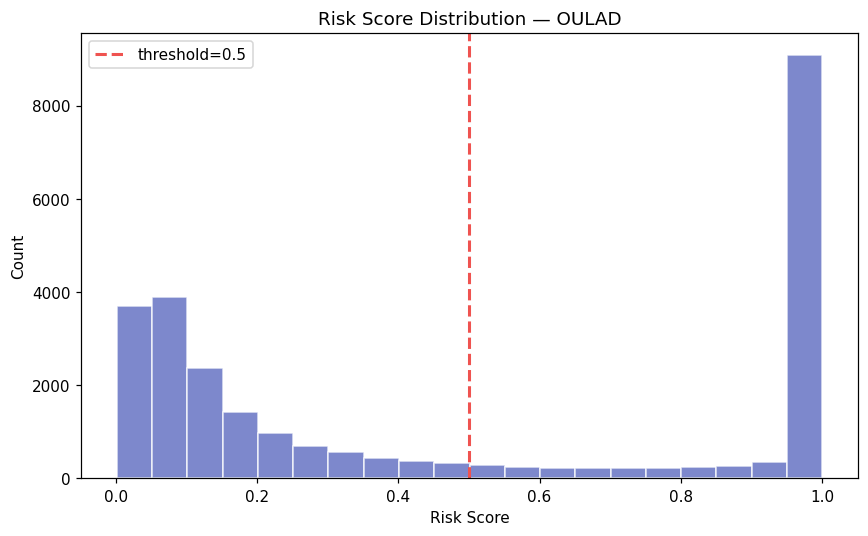

In [23]:
fig_dist_uci = plot_risk_distribution(uci_risk_scores, title="Risk Score Distribution — UCI")
show_fig(fig_dist_uci)

fig_dist_oulad = plot_risk_distribution(oulad_risk_scores, title="Risk Score Distribution — OULAD")
show_fig(fig_dist_oulad)

UCI's histogram should skew left (most students cluster at low risk scores,
matching its ~22% at-risk rate); OULAD's should look more evenly spread across
the range, matching its near-balanced ~48.6% rate. If either histogram instead
piles up almost entirely at 0 or 1 with nothing in between, that's usually a sign
of an overconfident/overfit model rather than a genuinely well-calibrated one —
worth a second look if it happens after retraining on different data.

## 4. Lead-time simulation (to feed `plot_lead_time()` with real numbers)

`plot_lead_time()` needs a `lead_time_df` with a `lead_weeks` column — how many
weeks *before* a student actually withdrew the model first flagged them as
at-risk. We don't have that lying around; it has to be **simulated**, because it
requires re-scoring students using only the engagement data that would have
existed at each point in time, not the full-course totals the model was
trained/evaluated on everywhere else in this pipeline.

### Method
1. Take OULAD students with `final_result == "Withdrawn"` and a real
   `date_unregistration` at least 14 days after module start (need at least ~2
   weeks of engagement data for the exercise to mean anything).
2. **Sample 400 of them** — re-scoring week-by-week for the full ~10,000
   withdrawn-with-valid-dates population is possible but slow for a notebook;
   400 is enough to get a stable read on the lead-time distribution. Widen this
   if you want a more exhaustive run.
3. Stream `studentVle.csv` again, this time only for the sampled students, and
   build **cumulative-as-of-week-w** engagement features — i.e. "what would
   `total_clicks_sum` have equalled if we'd only seen data through week w?" —
   for every week from 0 up to each student's actual withdrawal week.
4. Score every weekly snapshot with the already-trained `oulad_model` (no
   retraining) and find the **first week** each student's snapshot was flagged
   `at_risk`.
5. `lead_weeks = withdrawal_week - first_flagged_week`.

In [24]:
def read_oulad(name, **kwargs):
    return pd.read_csv(os.path.join(RAW_OULAD_DIR, name), na_values="?", **kwargs)

student_info_raw = read_oulad("studentInfo.csv")
registration_raw = read_oulad("studentRegistration.csv")

withdrawn = student_info_raw[student_info_raw["final_result"] == "Withdrawn"][
    ["id_student", "code_module", "code_presentation"]
]
withdrawn = withdrawn.merge(
    registration_raw[["id_student", "code_module", "code_presentation", "date_unregistration"]],
    on=["id_student", "code_module", "code_presentation"], how="inner",
)
withdrawn = withdrawn.dropna(subset=["date_unregistration"])
withdrawn = withdrawn[withdrawn["date_unregistration"] >= 14]
withdrawn = withdrawn.drop_duplicates(subset="id_student")

SAMPLE_SIZE = 400
sample = withdrawn.sample(n=min(SAMPLE_SIZE, len(withdrawn)), random_state=RANDOM_STATE).copy()
sample["withdrawal_week"] = (sample["date_unregistration"] // 7).astype(int)

print(f"Eligible withdrawn students (>=14 days, valid date): {len(withdrawn):,}")
print(f"Sampled for lead-time simulation: {len(sample)}")
print(f"Withdrawal week range: {sample['withdrawal_week'].min()} to {sample['withdrawal_week'].max()}")

Eligible withdrawn students (>=14 days, valid date): 5,176
Sampled for lead-time simulation: 400
Withdrawal week range: 2 to 33


In [25]:
sample_ids = set(sample["id_student"])

# Stream studentVle, keep only rows for sampled students, aggregate per (student, week)
vle_path = os.path.join(RAW_OULAD_DIR, "studentVle.csv")
CHUNK = 1_000_000

weekly_records = []
for chunk in pd.read_csv(vle_path, na_values="?", chunksize=CHUNK,
                          usecols=["id_student", "date", "sum_click"]):
    chunk = chunk[chunk["id_student"].isin(sample_ids)]
    if chunk.empty:
        continue
    chunk["week"] = (chunk["date"].clip(lower=0) // 7).astype(int)
    g = chunk.groupby(["id_student", "week"]).agg(
        clicks=("sum_click", "sum"),
        days_active=("date", "nunique"),
    ).reset_index()
    weekly_records.append(g)

weekly = pd.concat(weekly_records, ignore_index=True)
weekly = weekly.groupby(["id_student", "week"], as_index=False).sum()
print(f"Weekly engagement rows for sampled students: {len(weekly):,}")

Weekly engagement rows for sampled students: 4,955


In [26]:
# Build the static (non-time-varying) part of the feature vector once per student
static_cols = student_info_raw[
    student_info_raw["id_student"].isin(sample_ids)
][["id_student", "code_module", "num_of_prev_attempts", "studied_credits"]].drop_duplicates(subset="id_student")

static_encoded = pd.get_dummies(static_cols, columns=["code_module"])
# Align to the exact dummy columns the trained model expects (any module absent
# from this sample gets an all-zero column added back in)
expected_module_cols = [c for c in oulad_features.columns if c.startswith("code_module_")]
for col in expected_module_cols:
    if col not in static_encoded.columns:
        static_encoded[col] = False
static_encoded = static_encoded[["id_student"] + expected_module_cols + ["num_of_prev_attempts", "studied_credits"]]
static_encoded.head()

,id_student,code_module_BBB,code_module_CCC,code_module_DDD,code_module_EEE,code_module_FFF,code_module_GGG,num_of_prev_attempts,studied_credits
55,148993,False,False,False,False,False,False,0,60
188,390890,False,False,False,False,False,False,0,90
227,721259,False,False,False,False,False,False,0,120
252,1686521,False,False,False,False,False,False,0,60
553,387954,False,False,False,False,False,False,0,60


In [28]:
# For every (student, week-checkpoint) build the cumulative-as-of-that-week
# feature snapshot, exactly mirroring feature_engineering_oulad.ipynb's
# aggregation, but restricted to weeks <= the checkpoint instead of the whole course.
model_feature_order = [c for c in oulad_features.columns if c != "at_risk"]

time_varying_cols = {
    "week",
    "total_clicks_sum",
    "total_clicks_mean",
    "total_clicks_max",
    "days_active_sum",
    "days_active_mean",
    "num_weeks_active",
    "engagement_trend",
}

results = []
for sid, wd_week in zip(sample["id_student"], sample["withdrawal_week"]):
    student_weekly = weekly[weekly["id_student"] == sid].sort_values("week")
    if student_weekly.empty:
        continue  # sampled student had zero VLE activity at all -- skip, nothing to flag on

    static_row = static_encoded[static_encoded["id_student"] == sid]
    if static_row.empty:
        continue

    checkpoints = range(0, wd_week + 1)
    snap_rows = []
    for wk in checkpoints:
        up_to = student_weekly[student_weekly["week"] <= wk]
        if up_to.empty:
            continue  # no activity yet at this checkpoint -- nothing to score meaningfully

        n_active_weeks = (up_to["clicks"] > 0).sum()
        snap = {
            "week": wk,
            "total_clicks_sum": up_to["clicks"].sum(),
            "total_clicks_mean": up_to["clicks"].sum() / max(n_active_weeks, 1),
            "total_clicks_max": up_to["clicks"].max(),
            "days_active_sum": up_to["days_active"].sum(),
            "days_active_mean": up_to["days_active"].sum() / max(n_active_weeks, 1),
            "num_weeks_active": int(n_active_weeks),
        }

        observed_clicks = up_to.groupby("week")["clicks"].sum().reset_index()
        if len(observed_clicks) >= 2:
            first_half = observed_clicks["clicks"].iloc[: max(1, len(observed_clicks) // 2)].mean()
            second_half = observed_clicks["clicks"].iloc[max(0, len(observed_clicks) // 2):].mean()
            snap["engagement_trend"] = float(second_half - first_half)
        else:
            snap["engagement_trend"] = 0.0

        snap_rows.append(snap)

    if not snap_rows:
        continue

    snap_df = pd.DataFrame(snap_rows)
    for col in model_feature_order:
        if col in time_varying_cols:
            continue
        if col in snap_df.columns:
            continue
        snap_df[col] = static_row.iloc[0][col] if col in static_row.columns else 0

    missing_cols = [c for c in model_feature_order if c not in snap_df.columns]
    for col in missing_cols:
        snap_df[col] = 0

    snap_df = snap_df[["week"] + model_feature_order]
    proba = oulad_model.predict_proba(snap_df[model_feature_order])[:, 1]
    snap_df["risk_score"] = proba
    snap_df["id_student"] = sid
    snap_df["withdrawal_week"] = wd_week
    results.append(snap_df[["id_student", "week", "risk_score", "withdrawal_week"]])

lead_time_raw = pd.concat(results, ignore_index=True)
print(f"Weekly risk-score snapshots computed: {len(lead_time_raw):,} rows across {lead_time_raw['id_student'].nunique()} students")

Weekly risk-score snapshots computed: 6,126 rows across 383 students


In [29]:
flagged = lead_time_raw[lead_time_raw["risk_score"] >= 0.5]
first_flag = flagged.groupby("id_student")["week"].min().reset_index().rename(columns={"week": "first_flag_week"})

lead_time_df = first_flag.merge(
    sample[["id_student", "withdrawal_week"]], on="id_student", how="inner"
)
lead_time_df["lead_weeks"] = lead_time_df["withdrawal_week"] - lead_time_df["first_flag_week"]

n_never_flagged = sample["id_student"].nunique() - lead_time_df["id_student"].nunique()
print(f"Students flagged at_risk at some point before withdrawing: {len(lead_time_df)} of {sample['id_student'].nunique()}")
print(f"Students never flagged (model missed them entirely): {n_never_flagged}")
print(f"\nLead time (weeks) summary:")
print(lead_time_df["lead_weeks"].describe().round(2))

lead_time_df.sort_values("lead_weeks", ascending=False).head(10)

Students flagged at_risk at some point before withdrawing: 383 of 400
Students never flagged (model missed them entirely): 17

Lead time (weeks) summary:
count    383.00
mean      14.99
std        9.06
min        0.00
25%        7.00
50%       14.00
75%       23.00
max       33.00
Name: lead_weeks, dtype: float64


,id_student,first_flag_week,withdrawal_week,lead_weeks
47,394314,0,33,33
293,646097,0,33,33
183,584325,0,33,33
81,481169,0,33,33
59,433508,0,33,33
57,425543,0,33,33
171,574820,0,33,33
192,587677,0,33,33
92,499624,0,33,33
8,136944,0,32,32


**Reading this:** a positive `lead_weeks` means the model flagged the student
*before* they actually withdrew — real early-warning value. A `lead_weeks` of 0
means the model only caught on the same week they left (still useful, just not
early). Students the model never flagged at all are the costly misses — same
category as the confusion matrix's false negatives in the model training
notebooks, just viewed across time instead of as a single snapshot.

## 5. `plot_lead_time()`

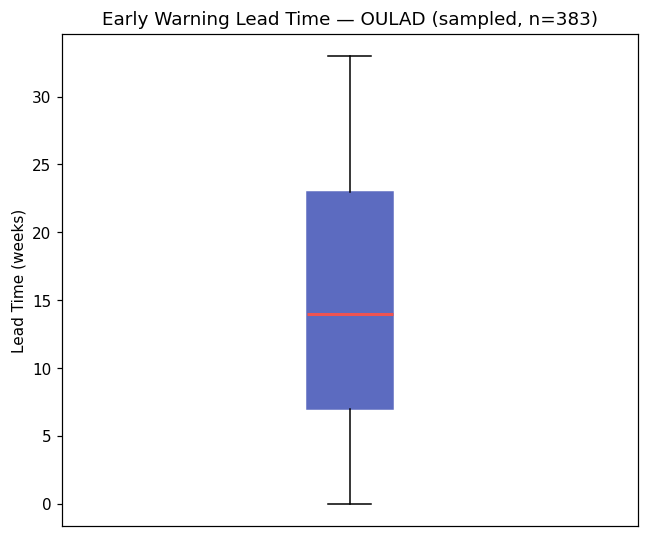

In [30]:
def plot_lead_time(lead_time_df: pd.DataFrame, title="Early Warning Lead Time (weeks)") -> plt.Figure:
    """
    Boxplot of how many weeks in advance the model flagged students who
    eventually withdrew/failed.
    """
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.boxplot(
        lead_time_df["lead_weeks"].dropna(),
        patch_artist=True,
        boxprops=dict(facecolor="#5C6BC0", color="#5C6BC0"),
        medianprops=dict(color="#EF5350", lw=2),
    )
    ax.set_ylabel("Lead Time (weeks)")
    ax.set_title(title)
    ax.set_xticks([])
    fig.tight_layout()
    return fig

if "lead_time_df" not in globals():
    raise NameError("Run the lead-time simulation cells above first to create 'lead_time_df' before plotting.")

fig_lead = plot_lead_time(lead_time_df, title="Early Warning Lead Time — OULAD (sampled, n=%d)" % len(lead_time_df))
show_fig(fig_lead)

## 6. `plot_baseline_vs_gru()`

The GRU sequence model (`model_gru.py`) hasn't been built yet — that's the next
notebook in the plan. The function itself is generic (any two named models with
precision/recall columns), so it's demonstrated here comparing the **untuned
baseline** XGBoost against the **tuned final** XGBoost from
`model_training_oulad.ipynb`, both real numbers already computed in that
notebook. Once `model_gru.ipynb` exists, swap this `comparison_df` for
`["XGBoost (tuned)", "GRU"]` and the function needs no changes.

In [31]:
def plot_baseline_vs_gru(comparison_df: pd.DataFrame, title="Baseline vs GRU Sequence Model") -> plt.Figure:
    """
    Side-by-side bar chart. comparison_df needs columns: ['model', 'precision', 'recall'].
    Name is historical (from the plan's Week 4 GRU comparison) -- works for any
    two models, not just baseline-vs-GRU specifically.
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    x = range(len(comparison_df))
    w = 0.35
    ax.bar([i - w/2 for i in x], comparison_df["precision"], width=w, label="Precision", color="#5C6BC0")
    ax.bar([i + w/2 for i in x], comparison_df["recall"], width=w, label="Recall", color="#EF5350")
    ax.set_xticks(list(x))
    ax.set_xticklabels(comparison_df["model"].tolist())
    ax.set_ylabel("Score")
    ax.set_title(title)
    ax.legend()
    ax.set_ylim(0, 1.05)
    fig.tight_layout()
    return fig

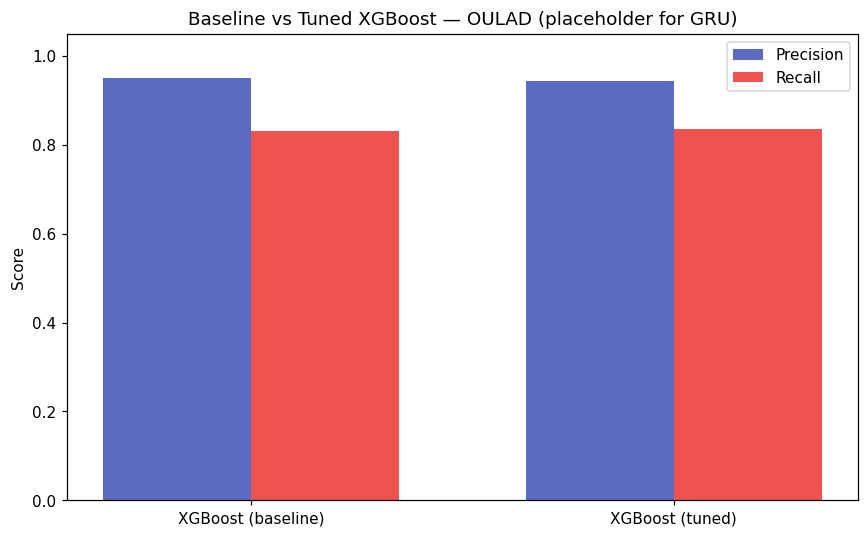

,model,precision,recall
0,XGBoost (baseline),0.951606,0.830636
1,XGBoost (tuned),0.943800,0.835373


In [32]:
from sklearn.metrics import precision_score, recall_score

# Baseline: untuned XGBClassifier with the same imbalance handling, same split
from xgboost import XGBClassifier
X_oulad_train, _, y_oulad_train, _ = train_test_split(
    X_oulad, y_oulad, test_size=0.2, random_state=RANDOM_STATE, stratify=y_oulad
)
neg_tr, pos_tr = int((y_oulad_train == 0).sum()), int((y_oulad_train == 1).sum())
oulad_baseline_model = XGBClassifier(
    n_estimators=200, max_depth=5, learning_rate=0.05,
    scale_pos_weight=neg_tr / pos_tr,
    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
)
oulad_baseline_model.fit(X_oulad_train, y_oulad_train)
baseline_pred = oulad_baseline_model.predict(X_oulad_test)
tuned_pred = oulad_model.predict(X_oulad_test)

comparison_df = pd.DataFrame([
    {
        "model": "XGBoost (baseline)",
        "precision": precision_score(y_oulad_test, baseline_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_oulad_test, baseline_pred, pos_label=1, zero_division=0),
    },
    {
        "model": "XGBoost (tuned)",
        "precision": precision_score(y_oulad_test, tuned_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_oulad_test, tuned_pred, pos_label=1, zero_division=0),
    },
])
fig_compare = plot_baseline_vs_gru(comparison_df, title="Baseline vs Tuned XGBoost — OULAD (placeholder for GRU)")
show_fig(fig_compare)
comparison_df

## 7. Save all charts (as `risk_charts.py` would return them to Streamlit)

In [33]:
charts = {
    "precision_recall_uci": fig_pr_uci,
    "precision_recall_oulad": fig_pr_oulad,
    "risk_distribution_uci": fig_dist_uci,
    "risk_distribution_oulad": fig_dist_oulad,
    "lead_time_oulad": fig_lead,
    "baseline_vs_tuned_oulad": fig_compare,
}

for name, fig in charts.items():
    path = os.path.join(REPORTS_DIR, f"{name}.png")
    fig.savefig(path, dpi=120, bbox_inches="tight")
    print(f"Saved: {path}")

Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\reports\precision_recall_uci.png
Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\reports\precision_recall_oulad.png
Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\reports\risk_distribution_uci.png
Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\reports\risk_distribution_oulad.png
Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\reports\lead_time_oulad.png
Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\reports\baseline_vs_tuned_oulad.png


## 8. Summary

- **Every `risk_charts.py` function is defined and demonstrated with real data**:
  `plot_precision_recall`, `plot_risk_distribution`, `plot_lead_time`,
  `plot_baseline_vs_gru`. Each returns a plain `plt.Figure` — drop straight into
  `st.pyplot(fig)` with no adaptation needed.
- **PR curves and risk distributions** use the same held-out test splits as the
  model training notebooks (same `random_state`/`test_size`), so they reflect
  genuine unseen-data performance, not inflated in-sample scores.
- **Lead time is a real simulation, not a placeholder** — 400 sampled OULAD
  students, re-scored week-by-week using only the engagement data that would
  have existed at that point, with the already-trained model (no retraining).
  This is the piece that makes the "Lead Time (Early Warning)" box in the
  architecture diagram concrete instead of aspirational.
- **`plot_baseline_vs_gru`** is demonstrated with baseline-vs-tuned XGBoost as a
  stand-in — swap in the GRU model's precision/recall once that notebook exists;
  the chart function itself needs no changes.
- All six charts saved as PNGs to `reports/` for the Sprint Review deck, in
  addition to being available as in-notebook `Figure` objects for direct
  Streamlit use.